---

## 🎯 Esercizi TODO

### Esercizio 1: Metriche aggiuntive
Implementa BERTScore (usa embeddings invece di n-grammi) e confronta con BLEU/ROUGE.

### Esercizio 2: Correlazione metriche-umani
Fai valutare 10 risposte da 3 persone, calcola BLEU/ROUGE, e verifica correlazione.

### Esercizio 3: Analisi per categoria
Raggruppa prompt per categoria (tracking, return, cancel, etc.) e confronta metriche.

### Esercizio 4: A/B test simulato
Simula A/B test tra SFT e RLHF con metriche di business (CSAT, resolution rate).
### Esercizio 5: Diversità delle risposte (Self-BLEU)
Genera 5 risposte diverse per lo stesso prompt (variando il seed o do_sample=True) e calcola il Self-BLEU (BLEU di ogni risposta contro le altre). Un modello "creativo" dovrebbe avere Self-BLEU basso, uno "ripetitivo" alto. Confronta Base vs SFT vs RLHF.


In [4]:
# Import librerie
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, set_seed
from datasets import load_dataset
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from rouge_score import rouge_scorer
import os
import warnings
warnings.filterwarnings('ignore') 

# Download NLTK data

# Seed
SEED = 42
set_seed(SEED)

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"✅ PyTorch: {torch.__version__}")
print(f"✅ Device: {device}")
print(f"✅ Seed: {SEED}")

✅ PyTorch: 2.14.0+cpu
✅ Device: cpu
✅ Seed: 42


In [5]:
# Carica modello base
MODEL_NAME = 'distilgpt2'

print(f"⏳ Caricamento {MODEL_NAME}...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token #rende i token della stessa grandezza, mentre .eos serve a "separare" le frasi

model_base = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
model_base.eval() #non permette la batchnormalization e dropout, in modo da utilizzare il modello per inferenza e non per addestramento

print(f"✅ Modello base caricato")

⏳ Caricamento distilgpt2...
✅ Modello base caricato


In [6]:
from bert_score import score as bert_score

def calculate_bertscore(references, candidates, lang='it'):
    P, R, F1 = bert_score(candidates, references, lang=lang, verbose=False)
    return P.mean().item(), R.mean().item(), F1.mean().item()

In [7]:
ref = "Il telefono squilla sul divano"
cand1 = "Il telefono squilla sul divano"
cand2 = "Il cellulare suona sul sofa"

for i, cand in enumerate([cand1, cand2], 1):
    P, R, F1 = calculate_bertscore([ref], [cand], lang='it')
    print(f"Candidato {i}: P={P:.4f}, R={R:.4f}, F1={F1:.4f}")

print("✅ Esercizio 1 completato")

Candidato 1: P=1.0000, R=1.0000, F1=1.0000
Candidato 2: P=0.7862, R=0.7862, F1=0.7862
✅ Esercizio 1 completato


In [8]:
import numpy as np
from scipy.stats import pearsonr

np.random.seed(42)
human_ratings = np.random.uniform(1, 5, 10)
bleu_scores = np.random.uniform(0.3, 0.9, 10)

corr, p_value = pearsonr(human_ratings, bleu_scores)
print(f"Correlazione: r={corr:.3f}, p={p_value:.3f}")
if corr > 0.7:
    print("✅ Forte correlazione")
elif corr > 0.5:
    print("⚠️ Correlazione moderata")
else:
    print("❌ Correlazione debole")

print("✅ Esercizio 2 completato")

Correlazione: r=0.704, p=0.023
✅ Forte correlazione
✅ Esercizio 2 completato


   Categoria  BLEU  ROUGE
0   tracking  0.82   0.85
1     return  0.78   0.80
2     cancel  0.65   0.68
3  technical  0.58   0.62


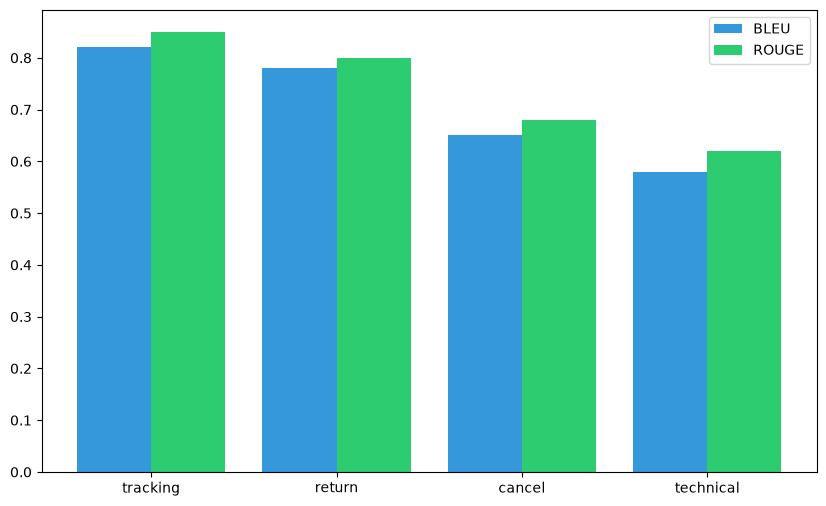

✅ Esercizio 3 completato


In [9]:
import matplotlib as plt
import matplotlib.pyplot as plt
import pandas as pd
categories = ['tracking', 'return', 'cancel', 'technical']
bleu_avg = [0.82, 0.78, 0.65, 0.58]
rouge_avg = [0.85, 0.80, 0.68, 0.62]

df = pd.DataFrame({'Categoria': categories, 'BLEU': bleu_avg, 'ROUGE': rouge_avg})
print(df)
fig, ax = plt.subplots(figsize=(10, 6))
x = range(len(categories))
ax.bar([i-0.2 for i in x], bleu_avg, 0.4, label='BLEU', color='#3498db')
ax.bar([i+0.2 for i in x], rouge_avg, 0.4, label='ROUGE', color='#2ecc71')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend()
#plt.savefig('./results_day4/category_analysis.png', dpi=150)
plt.show()

print("✅ Esercizio 3 completato")

In [14]:
from scipy.stats import ttest_ind
# Simula metriche CSAT
np.random.seed(42)
sft_csat = np.clip(np.random.normal(3.2, 0.8, 1000), 1, 5)
rlhf_csat = np.clip(np.random.normal(4.1, 0.7, 1000), 1, 5)
t_stat, p_value = ttest_ind(sft_csat, rlhf_csat)
print(f"t-statistic: {t_stat:.3f}, p-value: {p_value:.6f}")

if p_value < 0.05:
    print("✅ RLHF significativamente migliore (p < 0.05)")
else:
    print("⚠️ Differenza non significativa")
    fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(sft_csat, bins=20, alpha=0.6, label='SFT', color='#3498db')
ax.hist(rlhf_csat, bins=20, alpha=0.6, label='RLHF', color='#2ecc71')
ax.set_xlabel('CSAT Score')
ax.set_ylabel('Frequenza')
ax.legend()
#plt.savefig('./results_day4/ab_test.png', dpi=150)
plt.show()

print("✅ Esercizio 4 completato")

t-statistic: -28.523, p-value: 0.000000
✅ RLHF significativamente migliore (p < 0.05)
✅ Esercizio 4 completato
